# Errores, estabilidad e interpretación

Estos notebooks documentan experimentos ejecutados y leen sus artefactos. El entrenamiento completo se reproduce con `scripts/run_experiments.py`; las celdas de revisión no ajustan modelos ni cambian la selección. El informe final y la presentación corresponden a una etapa posterior.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
OUT = ROOT / 'outputs'
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_rows', 30)
protocol = json.loads((ROOT/'experiments'/'protocol.json').read_text(encoding='utf-8'))

## Estabilidad temporal

Estos diagnósticos se calculan con el predictor congelado. Los resultados 2016 son una prueba de deterioro temporal, condicionados a que el préstamo ya tenga resultado terminal en el snapshot.

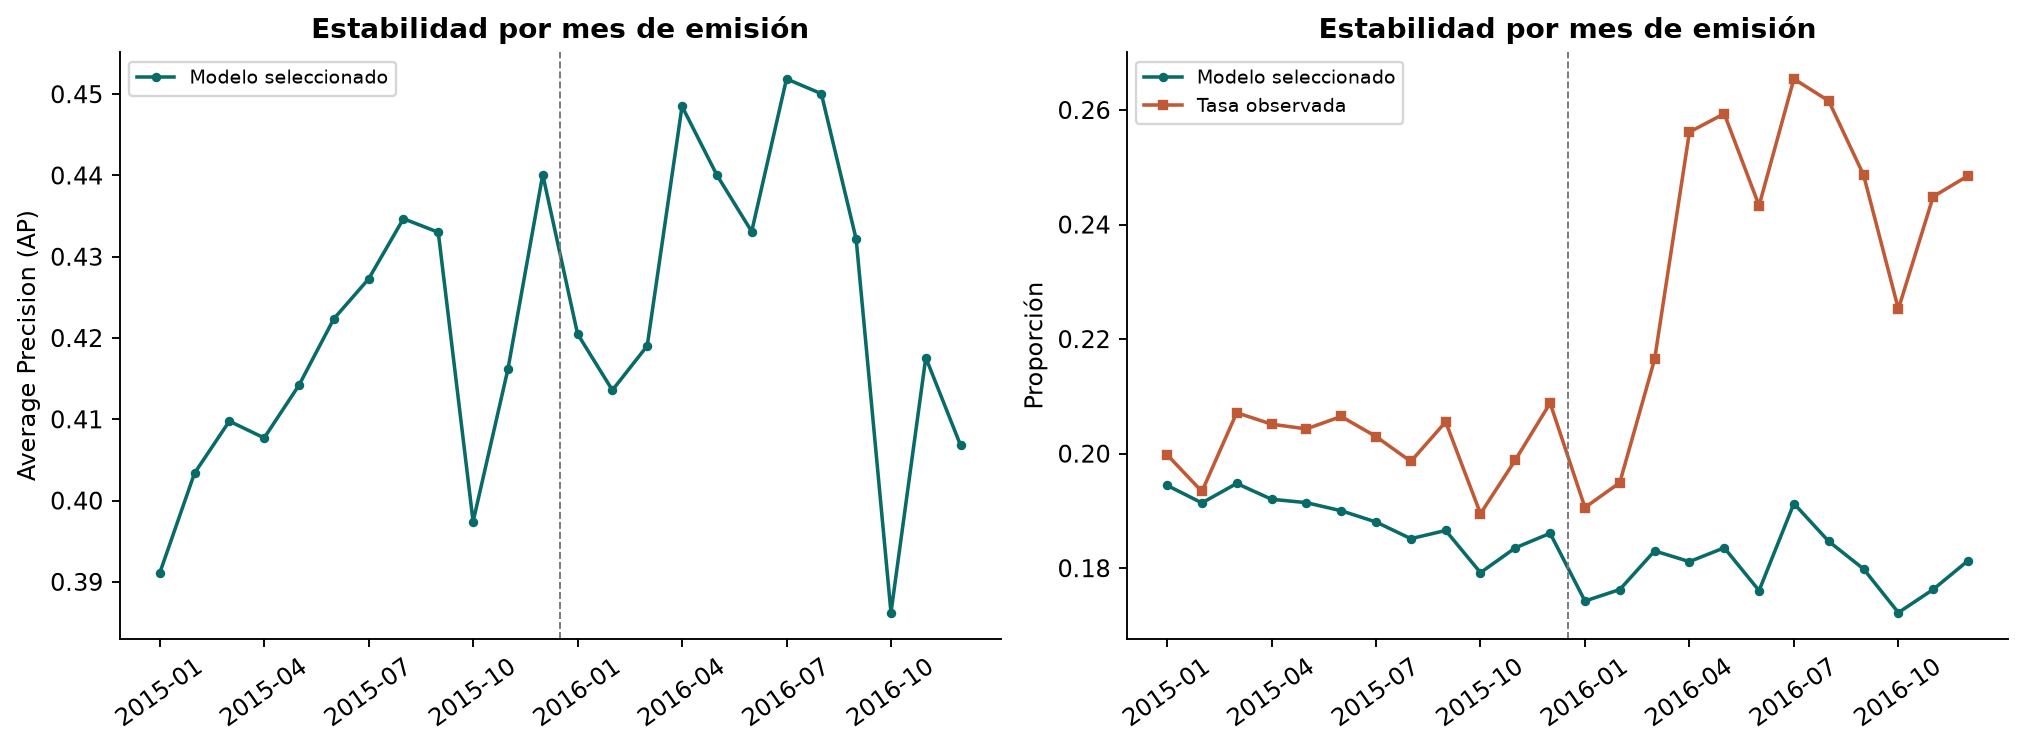

In [2]:
display(Image(filename=str(OUT/'figures'/'estabilidad_temporal.png')))

In [3]:
display(pd.read_csv(OUT/'analysis'/'distribution_drift.csv'))

,cohort,feature,PSI_nonmissing,missing_train,missing_test
0,2015,annual_inc,0.005013,0.000000,0.000006
1,2015,dti,0.076710,0.000000,0.000006
2,2015,fico_midpoint,0.025217,0.000000,0.000000
3,2015,loan_amnt,0.005459,0.000000,0.000000
4,2015,revol_util,0.025920,0.000678,0.000399
5,2015,credit_history_months,0.022339,0.000000,0.000000
6,2016,annual_inc,0.015336,0.000000,0.000108
7,2016,dti,0.063375,0.000000,0.000131
8,2016,fico_midpoint,0.014149,0.000000,0.000000
9,2016,loan_amnt,0.011511,0.000000,0.000000


## Lectura de los resultados observados

Un buen ordenamiento de riesgo no garantiza que el nivel de probabilidad siga calibrado al cambiar de año. La siguiente celda cuantifica la diferencia entre riesgo medio predicho y frecuencia observada en cada cohorte, sin volver a ajustar el calibrador.

In [4]:
reliability=pd.read_csv(OUT/'analysis'/'reliability.csv')
for year, group in reliability.query("model == 'selected' and mode == 'calibrated'").groupby('cohort'):
    predicted=(group.mean_prediction*group.n).sum()/group.n.sum()
    observed=(group.observed_rate*group.n).sum()/group.n.sum()
    print(f'{year}: riesgo medio predicho {predicted:.2%}; incumplimiento observado {observed:.2%}; diferencia observado-predicho {observed-predicted:+.2%}.')
print('Estas medias describen préstamos con resultado terminal; la cobertura limita su extrapolación.')

2015: riesgo medio predicho 18.80%; incumplimiento observado 20.14%; diferencia observado-predicho +1.35%.
2016: riesgo medio predicho 18.01%; incumplimiento observado 23.27%; diferencia observado-predicho +5.26%.
Estas medias describen préstamos con resultado terminal; la cobertura limita su extrapolación.


## Errores por segmentos

Se usa el umbral fijado en desarrollo. Se muestran FNR/FPR con intervalos Wilson. `low_support` marca segmentos con menos de 300 préstamos o menos de 30 ejemplos de alguna clase. Diferencias geográficas o socioeconómicas son señales para investigar: faltan atributos protegidos y solicitantes rechazados para una evaluación de equidad completa.

In [5]:
errors=pd.read_csv(OUT/'analysis'/'segment_errors.csv')
display(errors.query("cohort == 2015 and dimension in ['term','FICO','income','home_ownership','application_type','verification_status']")[[ 'dimension','segment','n','prevalence','AP','FNR','FPR','low_support']])
display(errors.query("cohort == 2015 and dimension == 'purpose' and low_support == False").sort_values('FNR', ascending=False)[['segment','n','AP','FNR','FPR']])

,dimension,segment,n,prevalence,AP,FNR,FPR,low_support
0,term,36 months,258856,0.148619,0.271797,0.609082,0.173351,False
1,term,60 months,84651,0.362996,0.531509,0.102610,0.723587,False
16,home_ownership,MORTGAGE,166622,0.175427,0.376167,0.434896,0.233776,False
17,home_ownership,RENT,139250,0.231662,0.454278,0.337239,0.335514,False
18,home_ownership,OWN,37633,0.204873,0.396467,0.388327,0.307623,False
19,home_ownership,ANY,2,0.000000,NaN,0.000000,0.500000,True
81,application_type,Individual,343132,0.201389,0.416530,0.384470,0.281197,False
82,application_type,Joint App,375,0.256000,0.398617,0.177083,0.594982,False
83,verification_status,Source Verified,149610,0.206744,0.414910,0.377324,0.292604,False
84,verification_status,Not Verified,92917,0.143698,0.320558,0.564560,0.159555,False


,segment,n,AP,FNR,FPR
13,vacation,2003,0.346971,0.527473,0.239170
8,car,2920,0.366492,0.473118,0.195519
3,credit_card,82427,0.381878,0.468338,0.204168
4,major_purchase,6123,0.408846,0.456319,0.218649
12,moving,2110,0.416590,0.449692,0.269871
6,home_improvement,20735,0.367913,0.448340,0.242308
7,medical,3361,0.413728,0.421348,0.283503
5,other,16484,0.406437,0.391584,0.302863
2,debt_consolidation,203100,0.431494,0.349641,0.317156
10,house,1221,0.433547,0.333333,0.360566


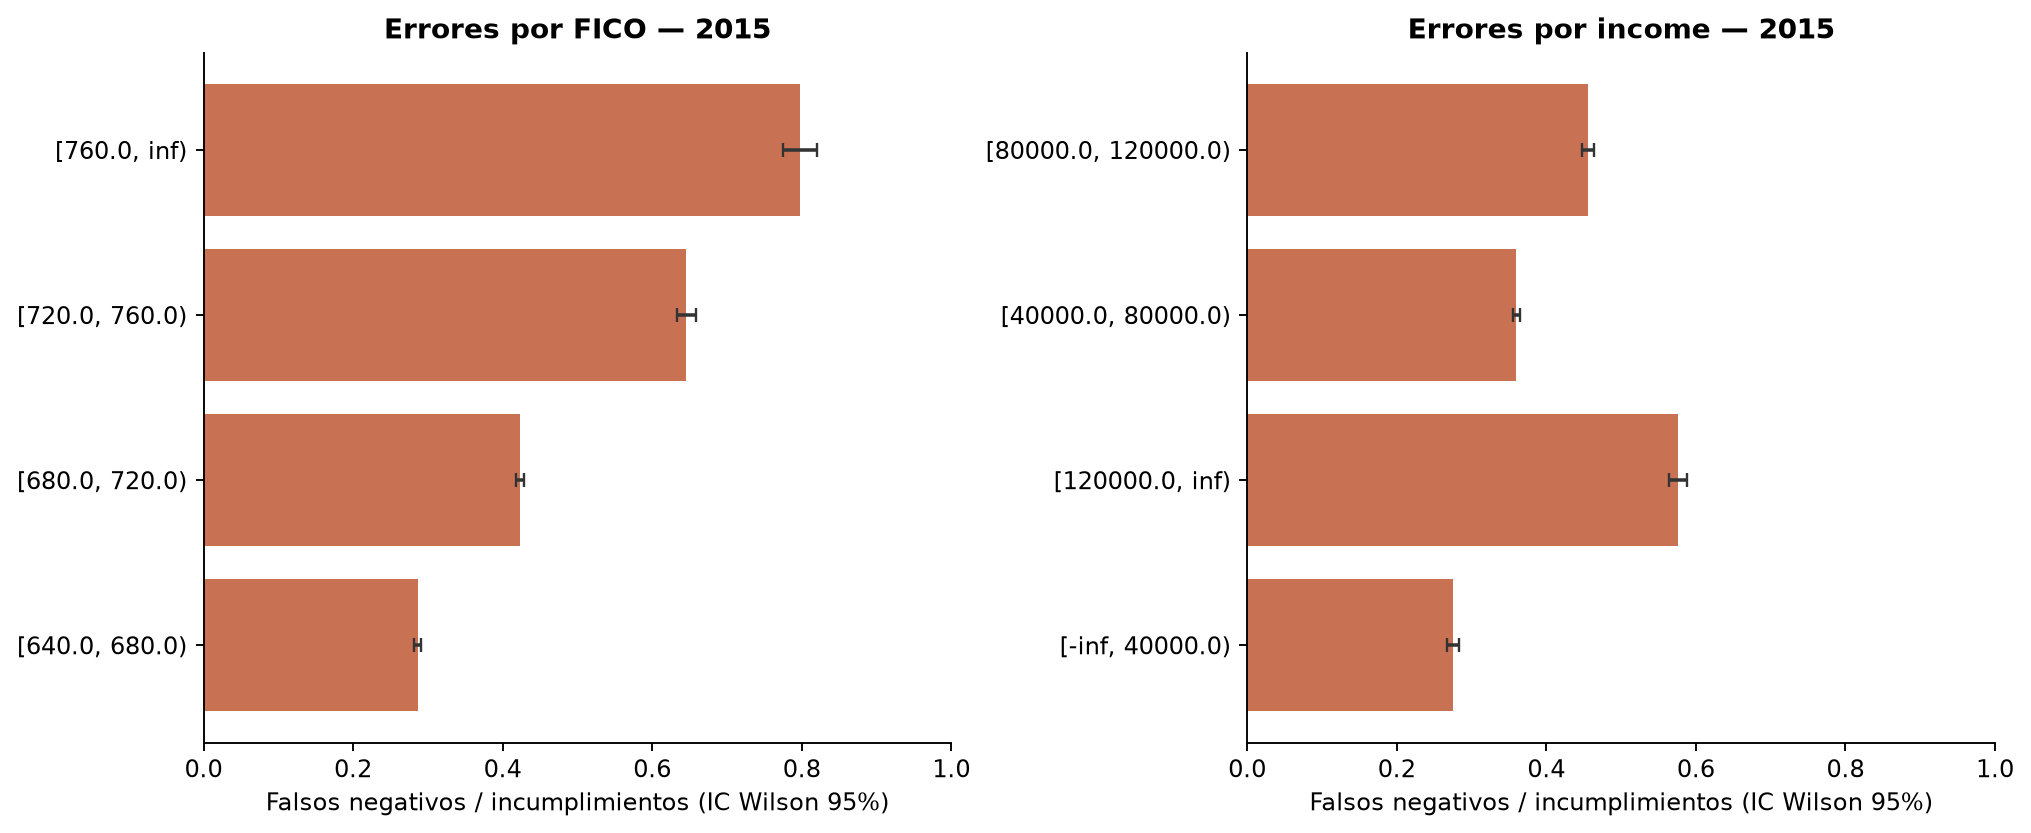

In [6]:
display(Image(filename=str(OUT/'figures'/'errores_segmentos.png')))

In [7]:
term_errors=errors.query("cohort == 2015 and dimension == 'term'")
for row in term_errors.itertuples():
    print(f'{row.segment}: se omite {row.FNR:.1%} de los incumplimientos y se marca como riesgoso {row.FPR:.1%} de los préstamos pagados con el umbral común de desarrollo.')
print('El umbral común produce compromisos distintos por plazo. Estos resultados son diagnósticos; no se optimizan nuevos umbrales con la prueba.')

36 months: se omite 60.9% de los incumplimientos y se marca como riesgoso 17.3% de los préstamos pagados con el umbral común de desarrollo.
60 months: se omite 10.3% de los incumplimientos y se marca como riesgoso 72.4% de los préstamos pagados con el umbral común de desarrollo.
El umbral común produce compromisos distintos por plazo. Estos resultados son diagnósticos; no se optimizan nuevos umbrales con la prueba.


## Importancia global del predictor final

La permutación se realiza sobre grupos de entradas originales; las variables derivadas se recalculan automáticamente. Se conservan correlaciones dentro del grupo permutado, pero se rompen dependencias con otros grupos. Su importancia no es un efecto causal.

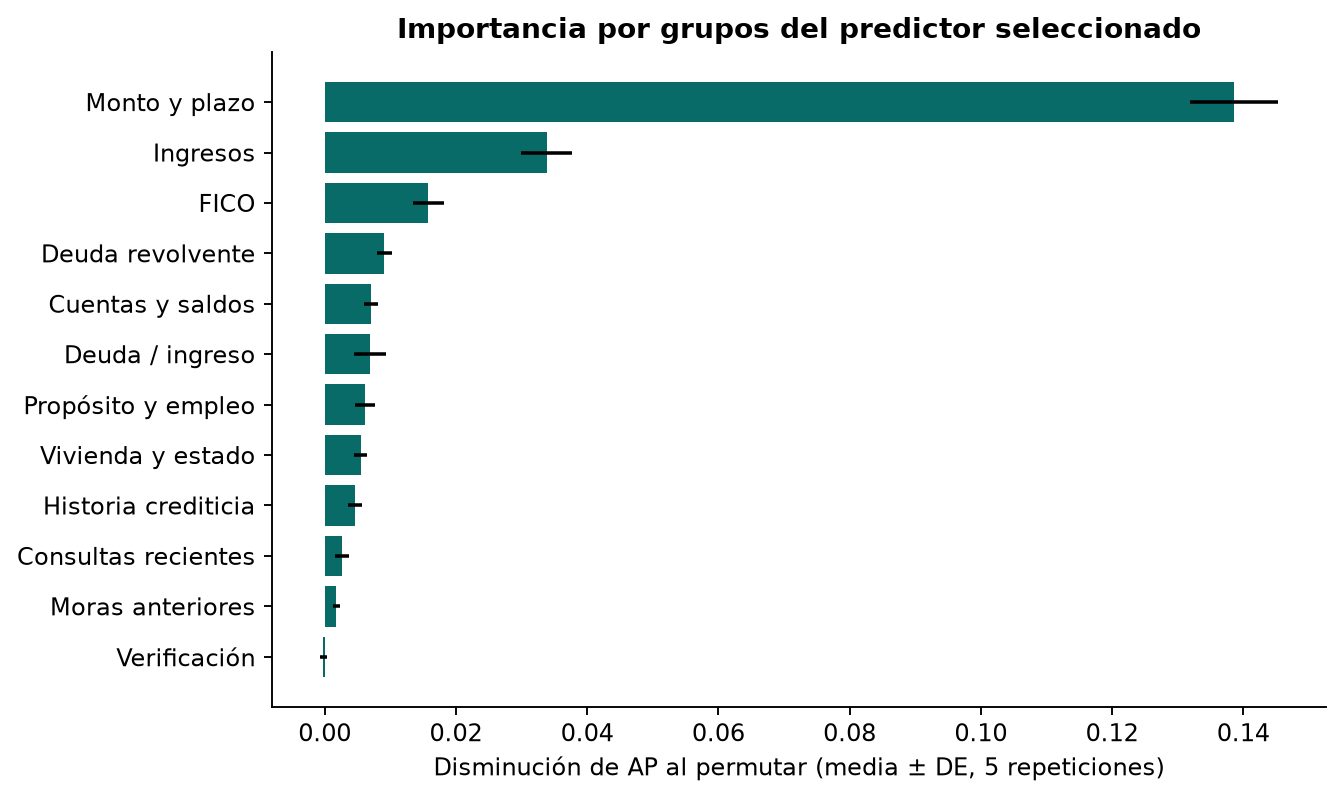

In [8]:
display(Image(filename=str(OUT/'figures'/'importancia_permutacion.png')))

In [9]:
importance=pd.read_csv(OUT/'analysis'/'grouped_permutation.csv')
display(importance.head(6))
print('Grupos cuya alteración más reduce AP:', ', '.join(importance.head(3)['group']))
print('La permutación mide dependencia predictiva en esta muestra; puede verse afectada por correlaciones entre grupos.')

,group,mean,std
0,Monto y plazo,0.138589,0.006710
1,Ingresos,0.033810,0.003880
2,FICO,0.015790,0.002308
3,Deuda revolvente,0.009034,0.001145
4,Cuentas y saldos,0.007020,0.001089
5,Deuda / ingreso,0.006892,0.002377


Grupos cuya alteración más reduce AP: Monto y plazo, Ingresos, FICO
La permutación mide dependencia predictiva en esta muestra; puede verse afectada por correlaciones entre grupos.


## Atribuciones globales y casos locales

Tree SHAP explica cada componente de boosting en log-odds. Se verifica su suma aditiva. La combinación de probabilidades y su calibración posterior no admiten sumar esas contribuciones como si fueran cambios de la probabilidad final. Los metadatos registran unidades, referencia y error de aditividad; la regresión usa descomposición lineal si fuera seleccionada.

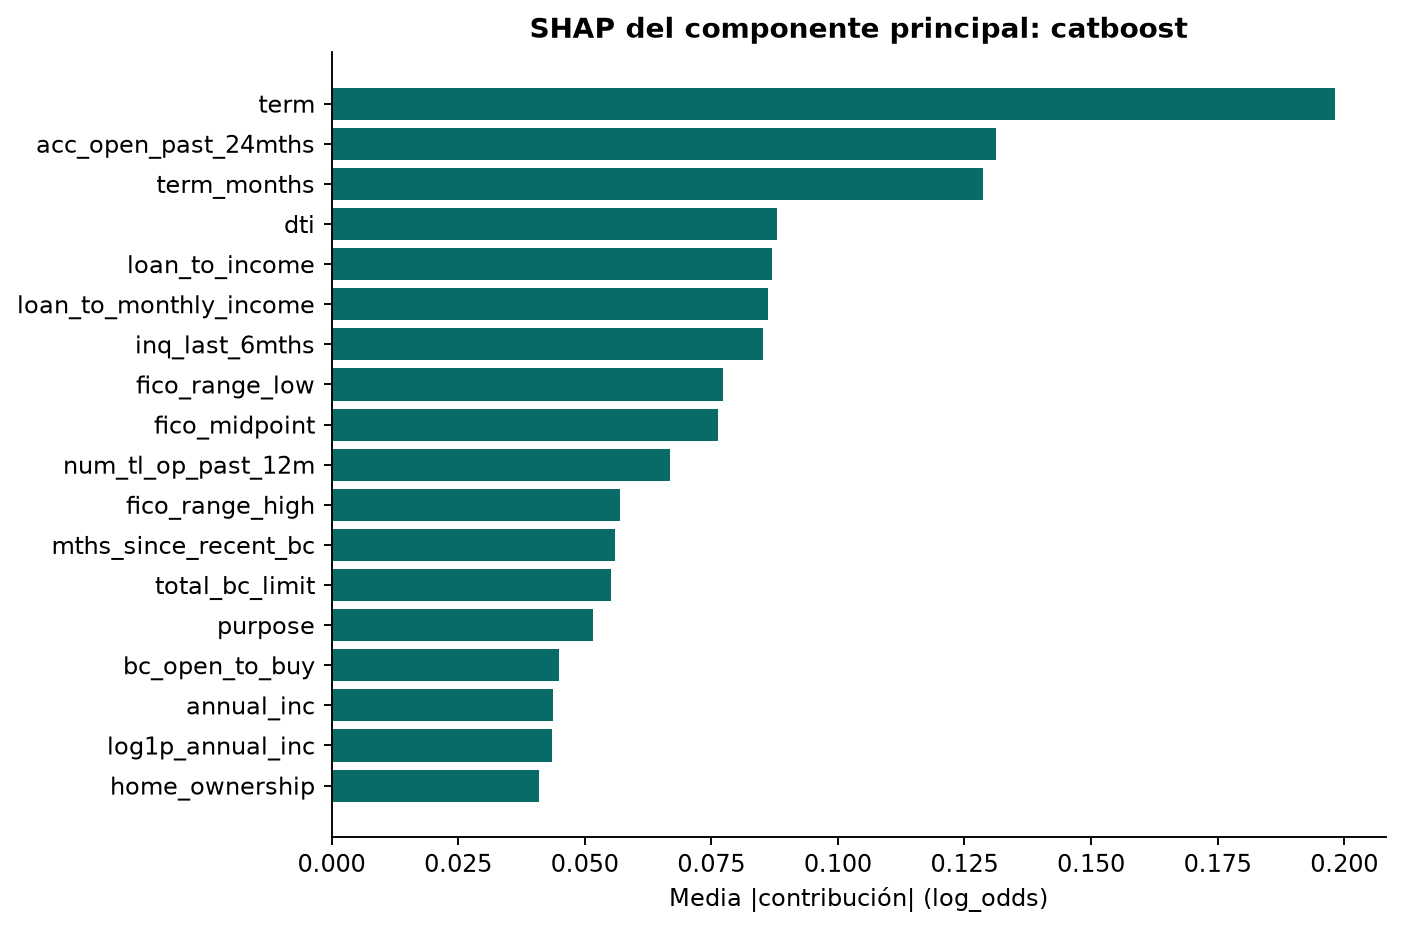

In [10]:
display(Image(filename=str(OUT/'figures'/'shap_global.png')))

In [11]:
metadata=json.loads((OUT/'analysis'/'explanation_metadata.json').read_text(encoding='utf-8'))
display(pd.DataFrame(metadata).T)
cases=json.loads((OUT/'analysis'/'local_cases.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{k:v for k,v in c.items() if k != 'top_contributions'} for c in cases]))

,family,weight,units,max_additivity_error,global_sample_n,explains,reference
catboost,catboost,0.2,log_odds,0.0,1200,uncalibrated component only; not additive to e...,tree-path-dependent
catboost_seed43,catboost,0.2,log_odds,0.0,1200,uncalibrated component only; not additive to e...,tree-path-dependent
catboost_seed44,catboost,0.2,log_odds,0.0,1200,uncalibrated component only; not additive to e...,tree-path-dependent
lightgbm,lightgbm,0.133333,log_odds,0.0,1200,uncalibrated component only; not additive to e...,tree-path-dependent
lightgbm_seed43,lightgbm,0.133333,log_odds,0.0,1200,uncalibrated component only; not additive to e...,tree-path-dependent
lightgbm_seed44,lightgbm,0.133333,log_odds,0.0,1200,uncalibrated component only; not additive to e...,tree-path-dependent


,id,case,component,component_weight,target,selected_probability,selected_threshold,component_raw_probability,base_value,sum_contributions,units
0,56129626,FP,catboost,0.200000,0,0.777325,0.208483,0.711449,-1.832415,2.734848,log_odds
1,40960541,FP,catboost,0.200000,0,0.765837,0.208483,0.755905,-1.832415,2.962772,log_odds
2,43661015,FP,catboost,0.200000,0,0.736264,0.208483,0.669744,-1.832415,2.539441,log_odds
3,44016868,FN,catboost,0.200000,1,0.009621,0.208483,0.010914,-1.832415,-2.674322,log_odds
4,67406916,FN,catboost,0.200000,1,0.010436,0.208483,0.011143,-1.832415,-2.653279,log_odds
...,...,...,...,...,...,...,...,...,...,...,...
67,55240726,TP,lightgbm_seed44,0.133333,1,0.806678,0.208483,0.658593,-1.820382,2.477410,log_odds
68,39732445,TP,lightgbm_seed44,0.133333,1,0.785522,0.208483,0.660780,-1.820382,2.487156,log_odds
69,58912781,TN,lightgbm_seed44,0.133333,0,0.007174,0.208483,0.017139,-1.820382,-2.228699,log_odds
70,51879140,TN,lightgbm_seed44,0.133333,0,0.007534,0.208483,0.016115,-1.820382,-2.291402,log_odds


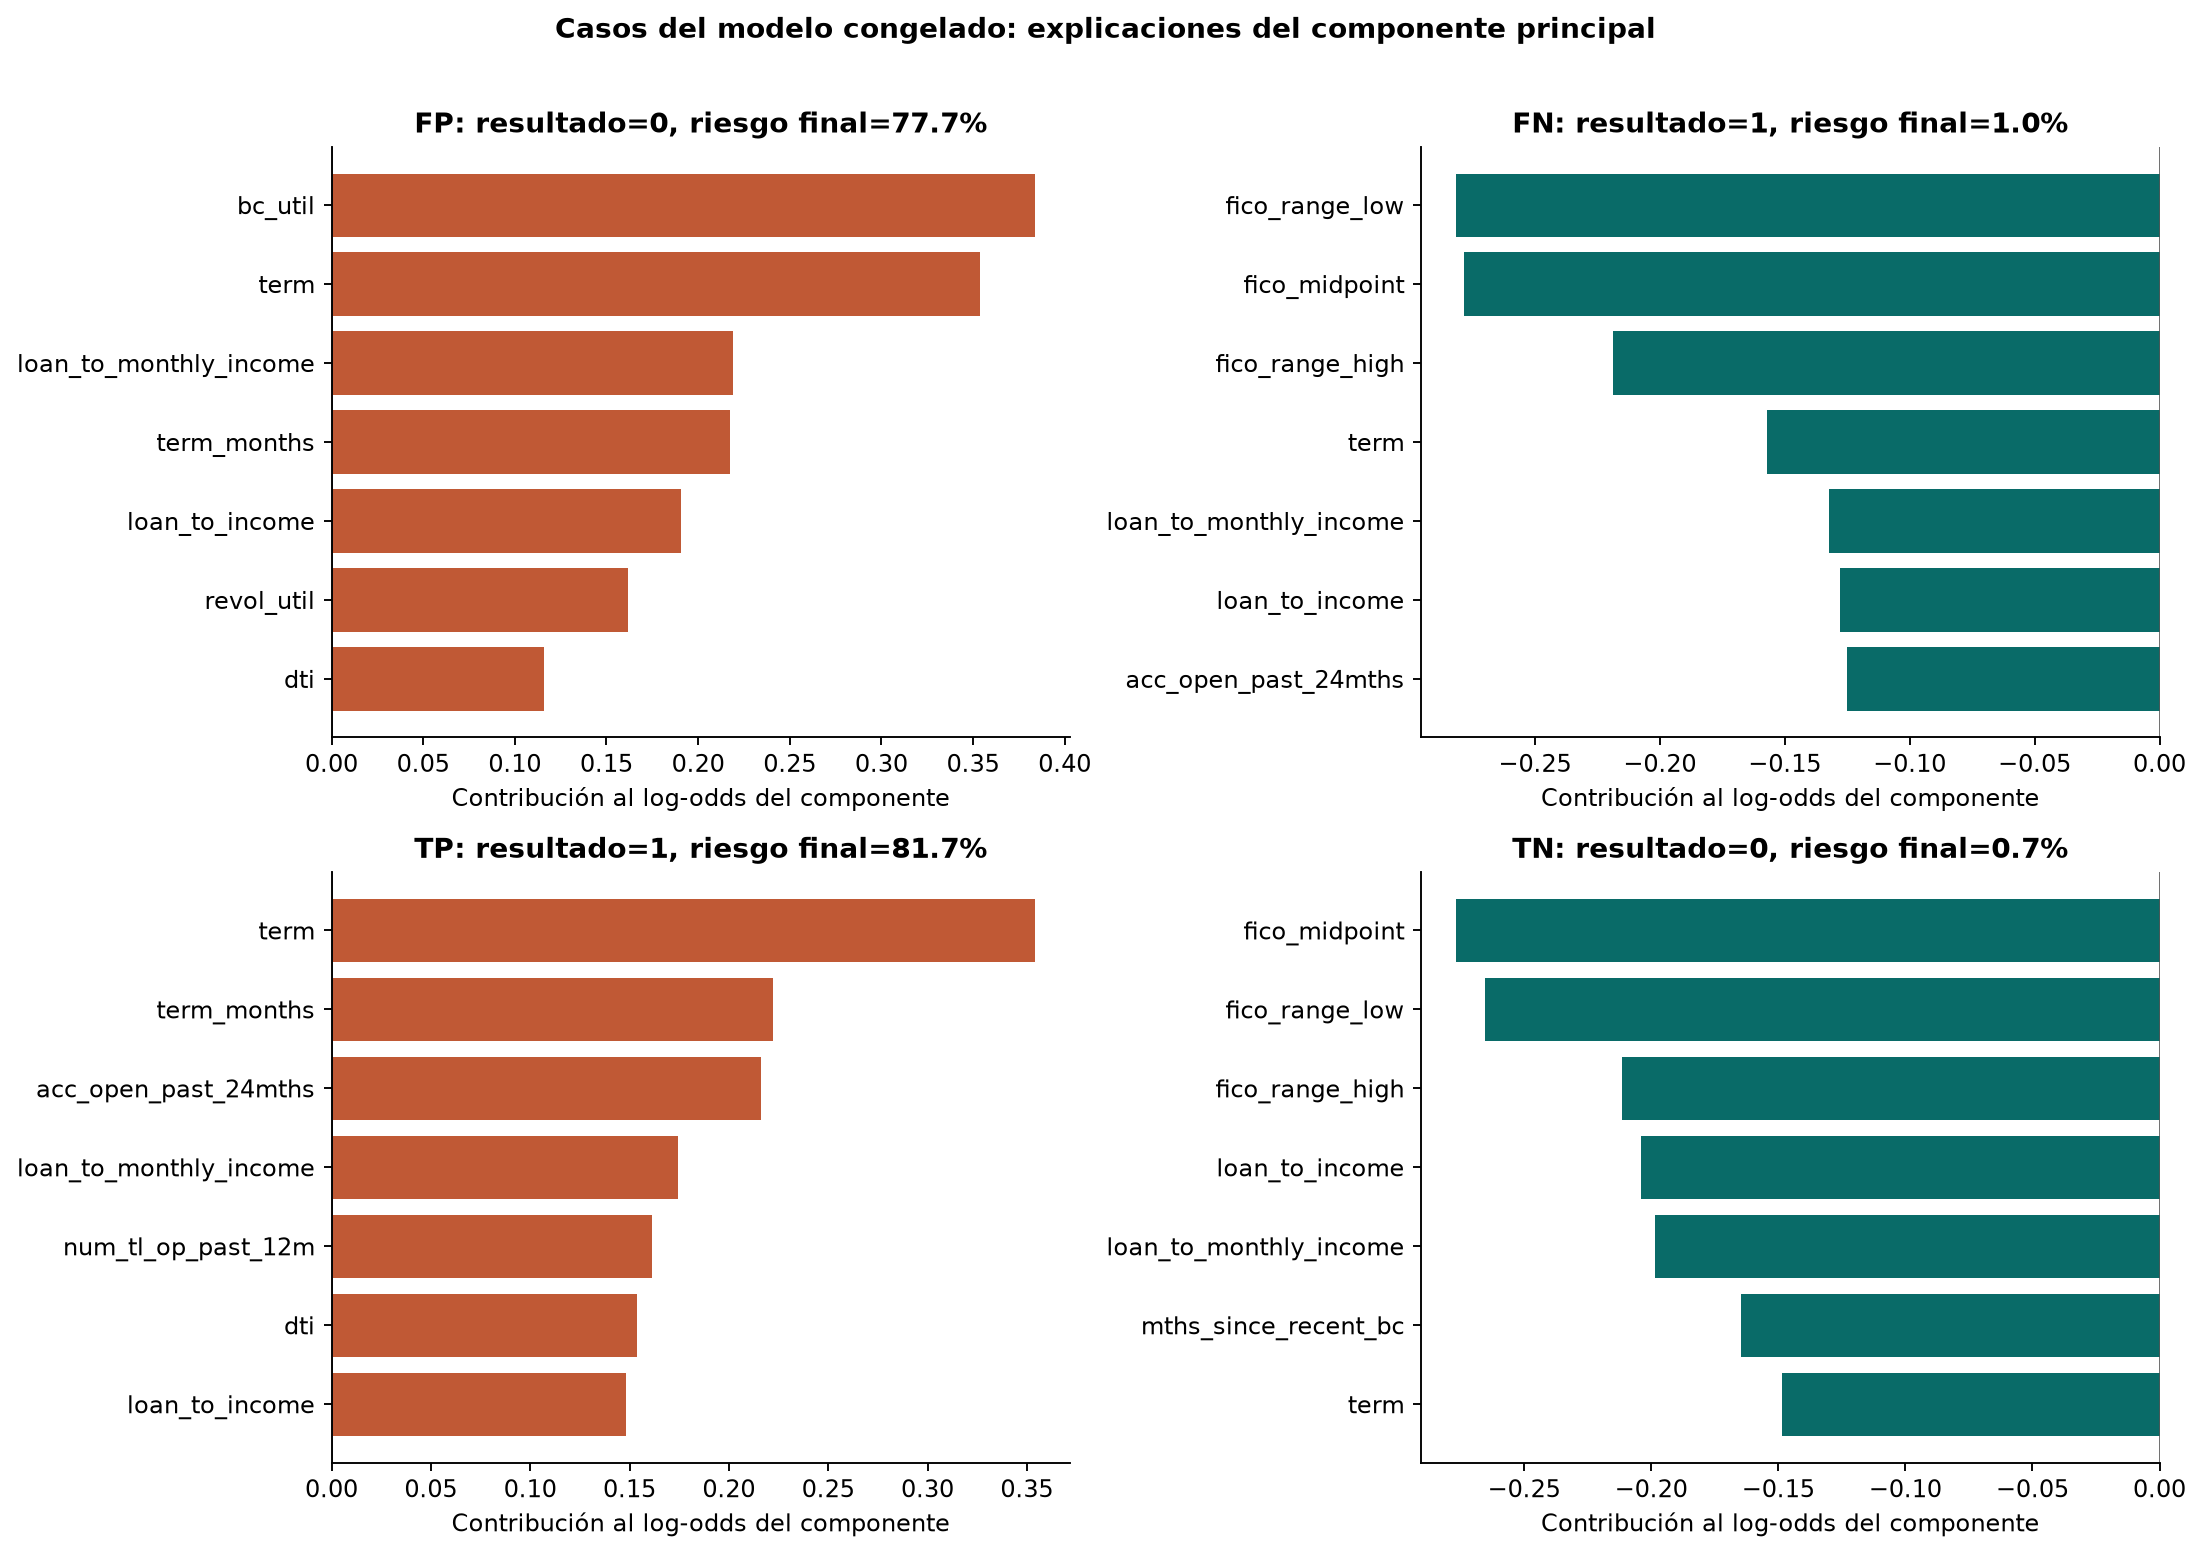

In [12]:
display(Image(filename=str(OUT/'figures'/'casos_locales.png')))

## Resistencia a entradas ausentes

Se ocultan aleatoriamente campos al predecir, usando el mismo modelo congelado. Es una perturbación sintética y no una garantía frente a faltantes sistemáticos del mundo real.

In [13]:
display(pd.read_csv(OUT/'analysis'/'missing_input_stress.csv')[[ 'scenario','fraction','AP','Brier','AP_delta_vs_intact','Brier_delta_vs_intact']])
display(pd.read_csv(OUT/'final'/'threshold_policies.csv')[[ 'cohort','policy','threshold','flag_rate','precision','recall','F1']])

,scenario,fraction,AP,Brier,AP_delta_vs_intact,Brier_delta_vs_intact
0,income_missing,0.1,0.413890,0.142329,-0.002778,0.000346
1,income_missing,0.3,0.402841,0.143693,-0.013827,0.001710
2,FICO_missing,0.1,0.417144,0.141796,0.000476,-0.000186
3,FICO_missing,0.3,0.413097,0.142200,-0.003571,0.000218
4,geography_missing,0.1,0.415804,0.142089,-0.000864,0.000107
5,geography_missing,0.3,0.415207,0.142205,-0.001461,0.000222
6,DTI_missing,0.1,0.415426,0.142142,-0.001242,0.000160
7,DTI_missing,0.3,0.415400,0.142462,-0.001268,0.000480


,cohort,policy,threshold,flag_rate,precision,recall,F1
0,2015,f1,0.208483,0.348860,0.355603,0.615818,0.450858
1,2015,recall60,0.220528,0.321437,0.366695,0.585110,0.450842
2,2015,capacity20,0.299472,0.184273,0.438206,0.400844,0.418693
3,2015,default,0.500000,0.031368,0.603155,0.093918,0.162528
4,2016,f1,0.208483,0.323306,0.392157,0.544893,0.456078
5,2016,recall60,0.220528,0.294913,0.403276,0.511133,0.450843
6,2016,capacity20,0.299472,0.159379,0.469494,0.321588,0.381714
7,2016,default,0.500000,0.024875,0.615535,0.065805,0.118899
